# 🩺 Predicción de Riesgo de Enfermedad Cardiovascular 
**Autor:** Jorge Sánchez Hernández  
**Proyecto:** Machine Learning supervisado  
**Datos:** Encuesta de Salud España 2025 *(Ministerio de Sanidad)*

## 2.1 Data cleansing 

In [1]:
#Librerias necesarias 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Carga de datos preprocesados en el notebook 01_Fuentes
df = pd.read_csv("../data/processed/ESdEadulto_2025_codigos.csv")
df_etiquetas = pd.read_csv("../data/processed/ESdEadulto_2025_etiquetas.csv")

Nuestra cohorte va a ser los que han contestado por si mismos. Eso corresponde a aquellos que ``PROXY_0 == 1.``

In [3]:
cohort = df["PROXY_0"] == 1          # solo quienes responden por sí mismos
df = df[cohort].drop(columns="PROXY_0") #la eliminamos porque ya no nos hace falta
df_etiquetas = df_etiquetas[cohort].drop(columns="PROXY_0")
print(df.shape)                           

(20357, 47)


Tenemos muchas columnas, asi que vamos agruparlas para organizar mejor nuestro estudio.

In [4]:
#Grupos de columnas
cols_ecv = ["infarto", "angina_y_otras_coronarias", "otra_cardiopatia", "ictus"]
cols_riesgo = ["tension_alta", "colesterol_alto", "diabetes", "epoc", "problemas_rinon",
                   "migrana", "tumor_maligno", "depresion", "ansiedad", "otros_problemas_mentales"]
cols_dieta = ["dieta_fruta", "dieta_verdura", "dieta_legumbres", "dieta_pescado",
              "dieta_carne_procesada", "dieta_dulces", "dieta_refrescos",
              "dieta_comida_rapida", "dieta_aperitivos"]

# Códigos de "No contesta" (cada grupo tiene el suyo. Se ha consultado en el excel diccionario)
cols_9 = (cols_ecv + cols_riesgo + cols_dieta +
          ["clase_social", "severidad_depresiva", "fuma", "humo_ajeno", "vapeo",
           "actividad_trabajo", "ejercicio_ocio", "dias_camina", "dias_deporte",
           "dias_fuerza", "apoyo_personas", "imc_categoria"])
cols_99 = ["nivel_estudios", "frec_alcohol", "frec_atracon_alcohol",
           "cigarrillos_dia", "sentado_h", "sentado_min"]
cols_999 = ["edad", "altura_cm", "peso_kg"]

 Blancos por flujo . Antes de no convertir los NC en NaN. Si la variable ``frec_atracon_alcohol``en blanco, significa que no bebió en los últimos 12 meses. Seleccionmos esas filas  (sin_beber),y se asigna a frec_atracon_alcohol el mismo valor (8 o 9) que tiene en frec_alcohol.

In [5]:
# Copiamos el código de frec_alcohol (8 = lo ha dejado, 9 = nunca)
sin_beber = df["frec_atracon_alcohol"].isna() & df["frec_alcohol"].isin([8, 9])
df.loc[sin_beber, "frec_atracon_alcohol"] = df.loc[sin_beber, "frec_alcohol"]
df["frec_atracon_alcohol"] = df["frec_atracon_alcohol"].fillna(99)  #quien no contestó

Comprobamos cuantos valores "No contesta" tenemos 

In [6]:
nc = pd.concat([(df[cols_9] == 9).sum(), (df[cols_99] == 99).sum(), (df[cols_999] == 999).sum()])
tabla_nc = pd.DataFrame({"No contesta": nc, "%": (nc / len(df) * 100).round(1)})
print(tabla_nc.sort_values("%", ascending=False).head(10))

                      No contesta     %
sentado_h                    2281  11.2
sentado_min                  2281  11.2
imc_categoria                1041   5.1
severidad_depresiva          1017   5.0
frec_atracon_alcohol         1002   4.9
actividad_trabajo             875   4.3
peso_kg                       843   4.1
dias_fuerza                   668   3.3
clase_social                  562   2.8
dias_camina                   549   2.7


Dejamos los "No Contesta" como categoría en las categóricas, en un principio. En las númericas lo ponemos como NaN.

In [7]:
df["edad"] = df["edad"].replace(999, np.nan)
df["altura_cm"] = df["altura_cm"].replace(999, np.nan)
df["peso_kg"] = df["peso_kg"].replace(999, np.nan)
df[["sentado_h", "sentado_min", "cigarrillos_dia"]] = df[["sentado_h", "sentado_min", "cigarrillos_dia"]].replace(99, np.nan)
df[["dias_camina", "dias_deporte", "dias_fuerza"]] = df[["dias_camina", "dias_deporte", "dias_fuerza"]].replace(9, np.nan)

In [8]:

# ---------- Si queremos poner los "No contesta" en todas las filas como NaN descomentamos esta fila----------
df[cols_9] = df[cols_9].replace(9, np.nan)
df[cols_99] = df[cols_99].replace(99, np.nan)
df[cols_999] = df[cols_999].replace(999, np.nan)



Definición de nuestra variable objetivo

In [9]:
# Sin saber si tiene ECV la fila no sirve, asi que se eliminan
df = df[(df[cols_ecv] != 9).all(axis=1)].copy()
df["ecv"] = (df[cols_ecv] == 1).any(axis=1).astype(int)
df = df.drop(columns=cols_ecv)
print(df["ecv"].value_counts(normalize=True).round(3))    # ~10 % de ECV

ecv
0    0.899
1    0.101
Name: proportion, dtype: float64


Recodificación de variables

In [10]:

# ---------- 6. Recodificar la variable sexo Sí/No (1/2) a 1/0  conservando los NaN ----------

df["mujer"] = df["sexo"].map({1: 0, 2: 1})

Creación de variables números

In [11]:
df["imc"] = df["peso_kg"] / (df["altura_cm"] / 100) ** 2
df = df.drop(columns=["sexo", "altura_cm", "peso_kg", "sentado_min"])

Realineamos en el otro df que tiene las etiquetas

In [12]:
df_etiquetas = df_etiquetas.loc[df.index]

Comprobaciones finales y guardados. 

In [13]:
print(df.shape)                                           # (20016, 42)
print(df.isna().mean().sort_values(ascending=False).head(8).round(3))
print(df[cols_riesgo + ["mujer", "ecv"]].apply(lambda s: sorted(s.dropna().unique())).to_dict())


df.to_csv("../data/processed/ecv_procesado.csv", index=False)
df_etiquetas.to_csv("../data/processed/ecv_procesado_etiquetas.csv", index=False)

(20357, 42)
sentado_h               0.112
imc                     0.051
imc_categoria           0.051
severidad_depresiva     0.050
frec_atracon_alcohol    0.049
actividad_trabajo       0.043
dias_fuerza             0.033
clase_social            0.028
dtype: float64
{'tension_alta': {0: 1.0, 1: 2.0}, 'colesterol_alto': {0: 1.0, 1: 2.0}, 'diabetes': {0: 1.0, 1: 2.0}, 'epoc': {0: 1.0, 1: 2.0}, 'problemas_rinon': {0: 1.0, 1: 2.0}, 'migrana': {0: 1.0, 1: 2.0}, 'tumor_maligno': {0: 1.0, 1: 2.0}, 'depresion': {0: 1.0, 1: 2.0}, 'ansiedad': {0: 1.0, 1: 2.0}, 'otros_problemas_mentales': {0: 1.0, 1: 2.0}, 'mujer': {0: 0, 1: 1}, 'ecv': {0: 0, 1: 1}}


## 2.2 Mini-EDA

ecv
0    18303
1     2054
Name: count, dtype: int64
Prevalencia en la muestra: 10.1 %
Prevalencia ponderada (población): 8.7 %


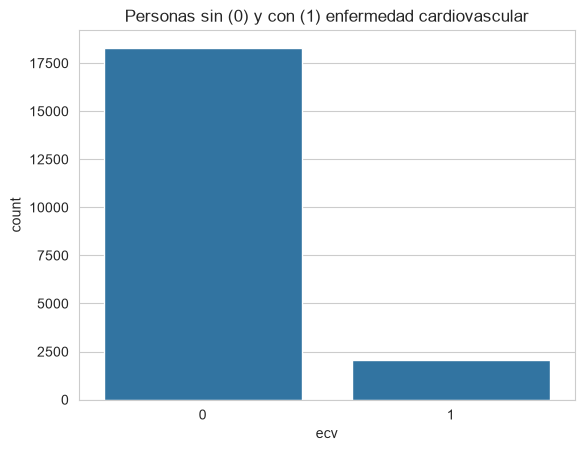

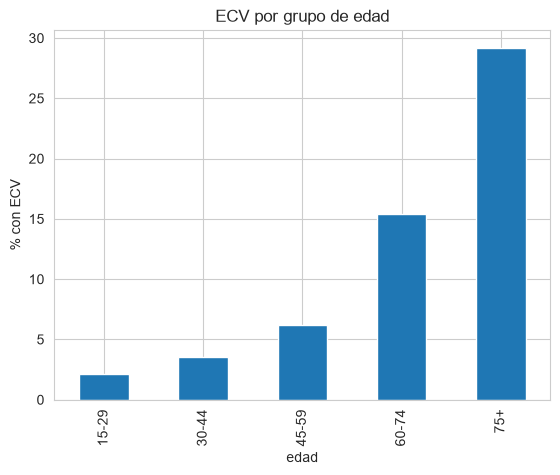

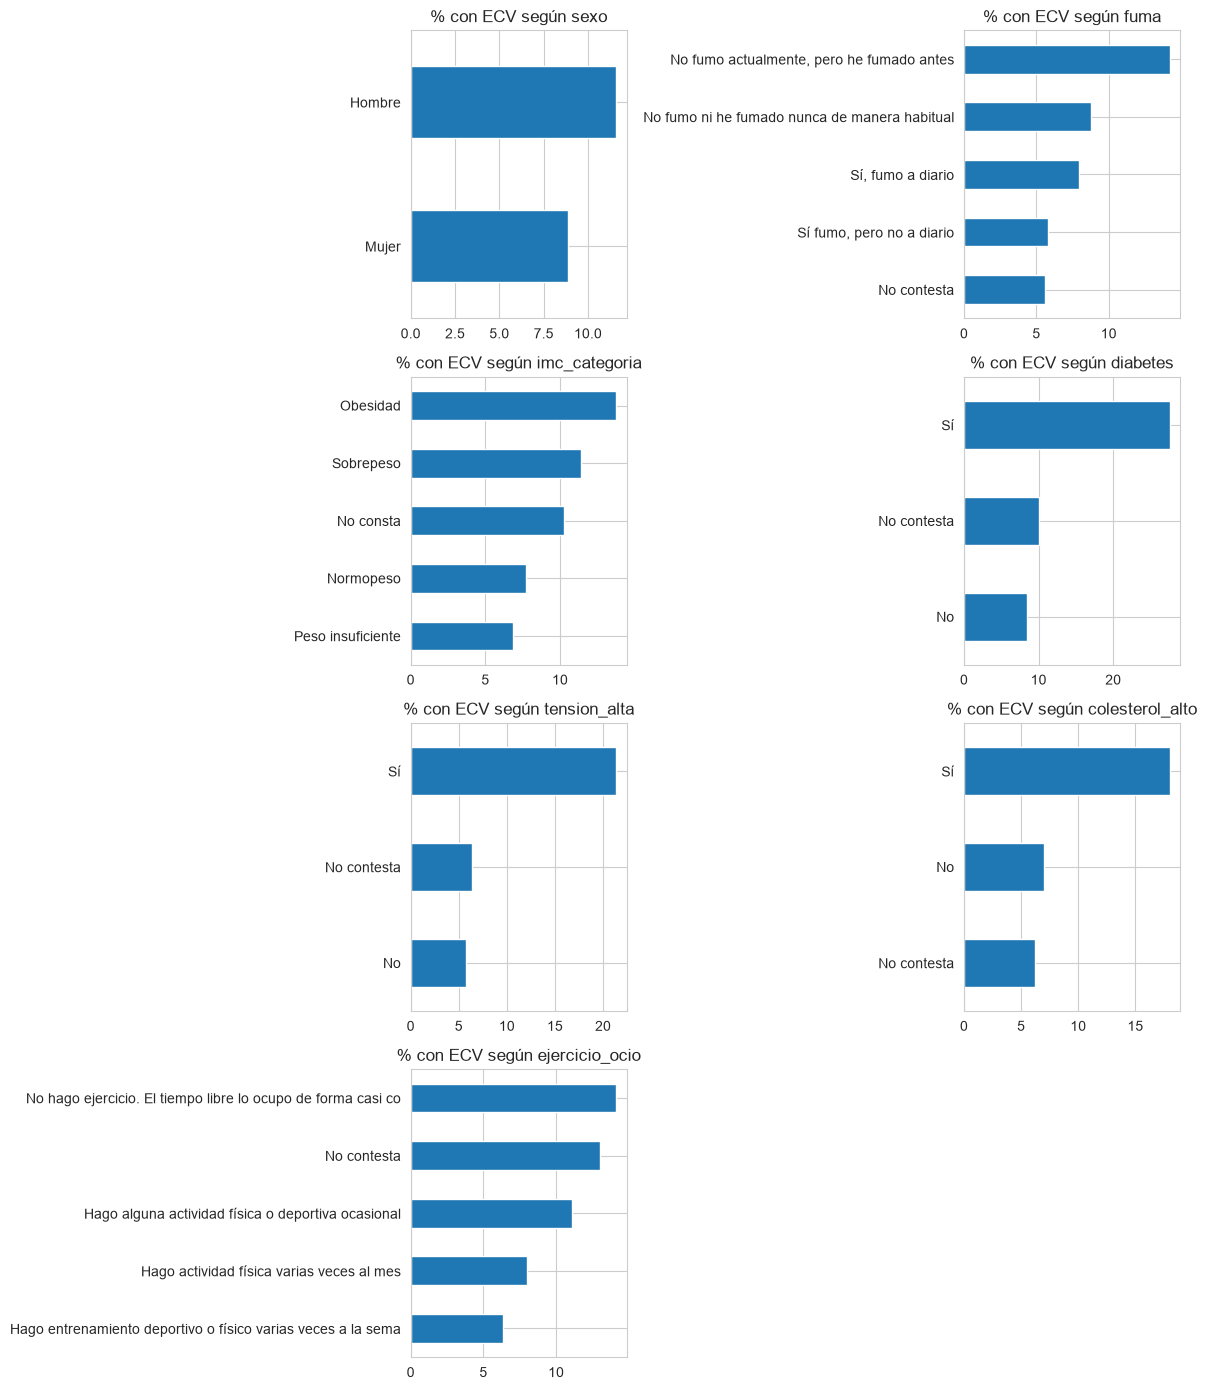

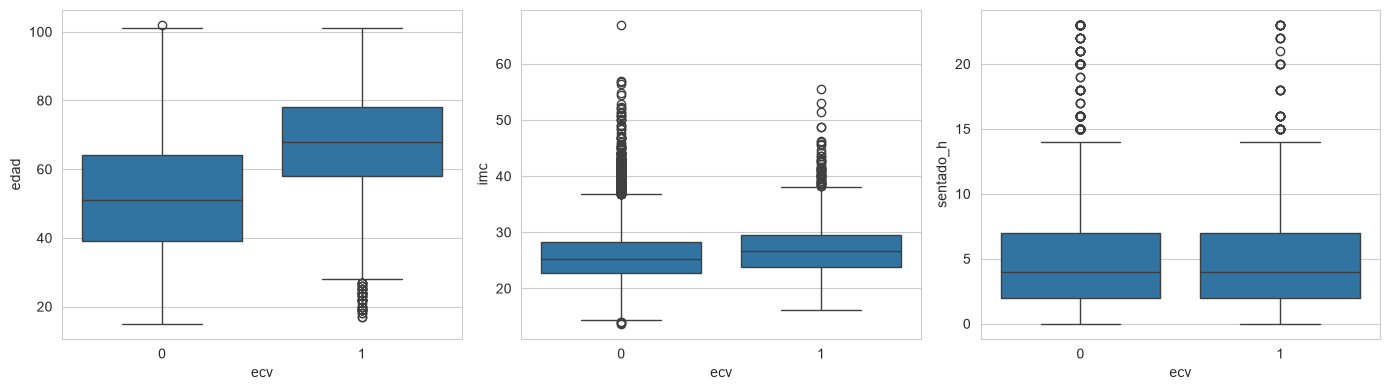

dias_deporte      -0.059
dias_camina       -0.046
dias_fuerza       -0.044
cigarrillos_dia   -0.027
sentado_h          0.017
imc                0.084
edad               0.262
Name: ecv, dtype: float64


In [14]:

sns.set_style("whitegrid")

# 1. Variable objetivo
print(df["ecv"].value_counts())
print("Prevalencia en la muestra:", round(df["ecv"].mean() * 100, 1), "%")
print("Prevalencia ponderada (población):",
      round(np.average(df["ecv"], weights=df["factor"]) * 100, 1), "%")
sns.countplot(x="ecv", data=df)
plt.title("Personas sin (0) y con (1) enfermedad cardiovascular")
plt.show()

# 2. ECV por grupo de edad
grupos_edad = pd.cut(df["edad"], bins=[14, 29, 44, 59, 74, 120],
                     labels=["15-29", "30-44", "45-59", "60-74", "75+"])
df.groupby(grupos_edad, observed=True)["ecv"].mean().mul(100).round(1).plot(kind="bar")
plt.ylabel("% con ECV")
plt.title("ECV por grupo de edad")
plt.show()

# 3. ECV según variables clave (con etiquetas legibles)
claves = ["sexo", "fuma", "imc_categoria", "diabetes", "tension_alta",
          "colesterol_alto", "ejercicio_ocio"]
fig, ejes = plt.subplots(4, 2, figsize=(12, 14))
for ax, col in zip(ejes.flatten(), claves):
    tasa = df["ecv"].groupby(df_etiquetas[col]).mean().mul(100).sort_values()
    tasa.plot(kind="barh", ax=ax)
    ax.set_title(f"% con ECV según {col}")
    ax.set_ylabel("")
ejes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

# 4. Variables numéricas frente a la ECV
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(ejes, ["edad", "imc", "sentado_h"]):
    sns.boxplot(x="ecv", y=col, data=df, ax=ax)
plt.tight_layout()
plt.show()

# 5. Correlación de las numéricas con la ECV
cols_num = ["edad", "imc", "sentado_h", "cigarrillos_dia",
            "dias_camina", "dias_deporte", "dias_fuerza"]
print(df[cols_num + ["ecv"]].corr()["ecv"].drop("ecv").sort_values().round(3))

Nos ayudamos de la ia para representar los gráficos de una manera mas visual y bonita

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

PALETA = "viridis"     # prueba también: "flare", "mako", "rocket", "viridis"

sns.set_theme(style="whitegrid", font_scale=1.1, rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9ca3af",
    "grid.color": "#e5e7eb",
    "axes.titleweight": "bold",
    "figure.dpi": 110,
})

def grafico_barras(serie, titulo, cmap=PALETA, horizontal=False, ordenar=True, ax=None):
    """Barras con degradado de color y el valor escrito en cada una."""
    if ordenar:
        serie = serie.sort_values()
    colores = sns.color_palette(cmap, n_colors=len(serie))
    ax = ax or plt.gca()
    etiquetas = serie.index.astype(str)
    if horizontal:
        ax.barh(etiquetas, serie.values, color=colores)
        for i, v in enumerate(serie.values):
            ax.text(v, i, f" {v:.1f}", va="center")
    else:
        ax.bar(etiquetas, serie.values, color=colores)
        for i, v in enumerate(serie.values):
            ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
    ax.set_title(titulo, loc="left")
    sns.despine(ax=ax)

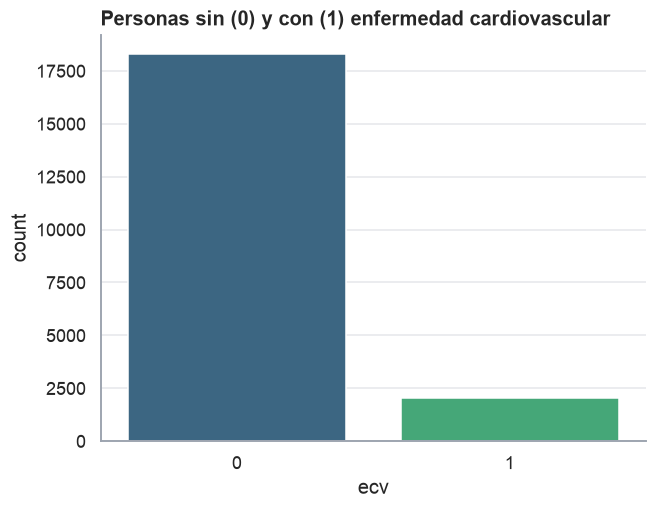

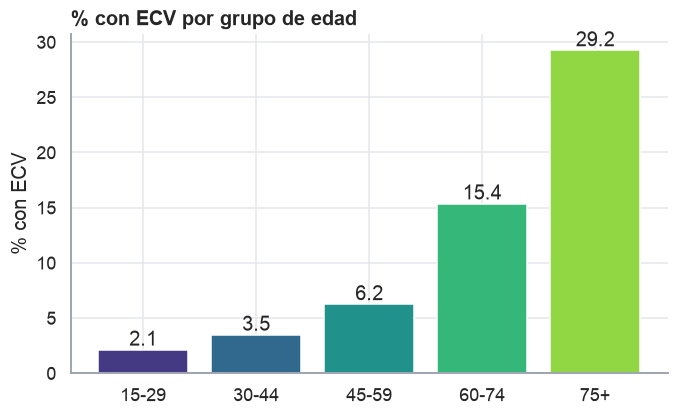

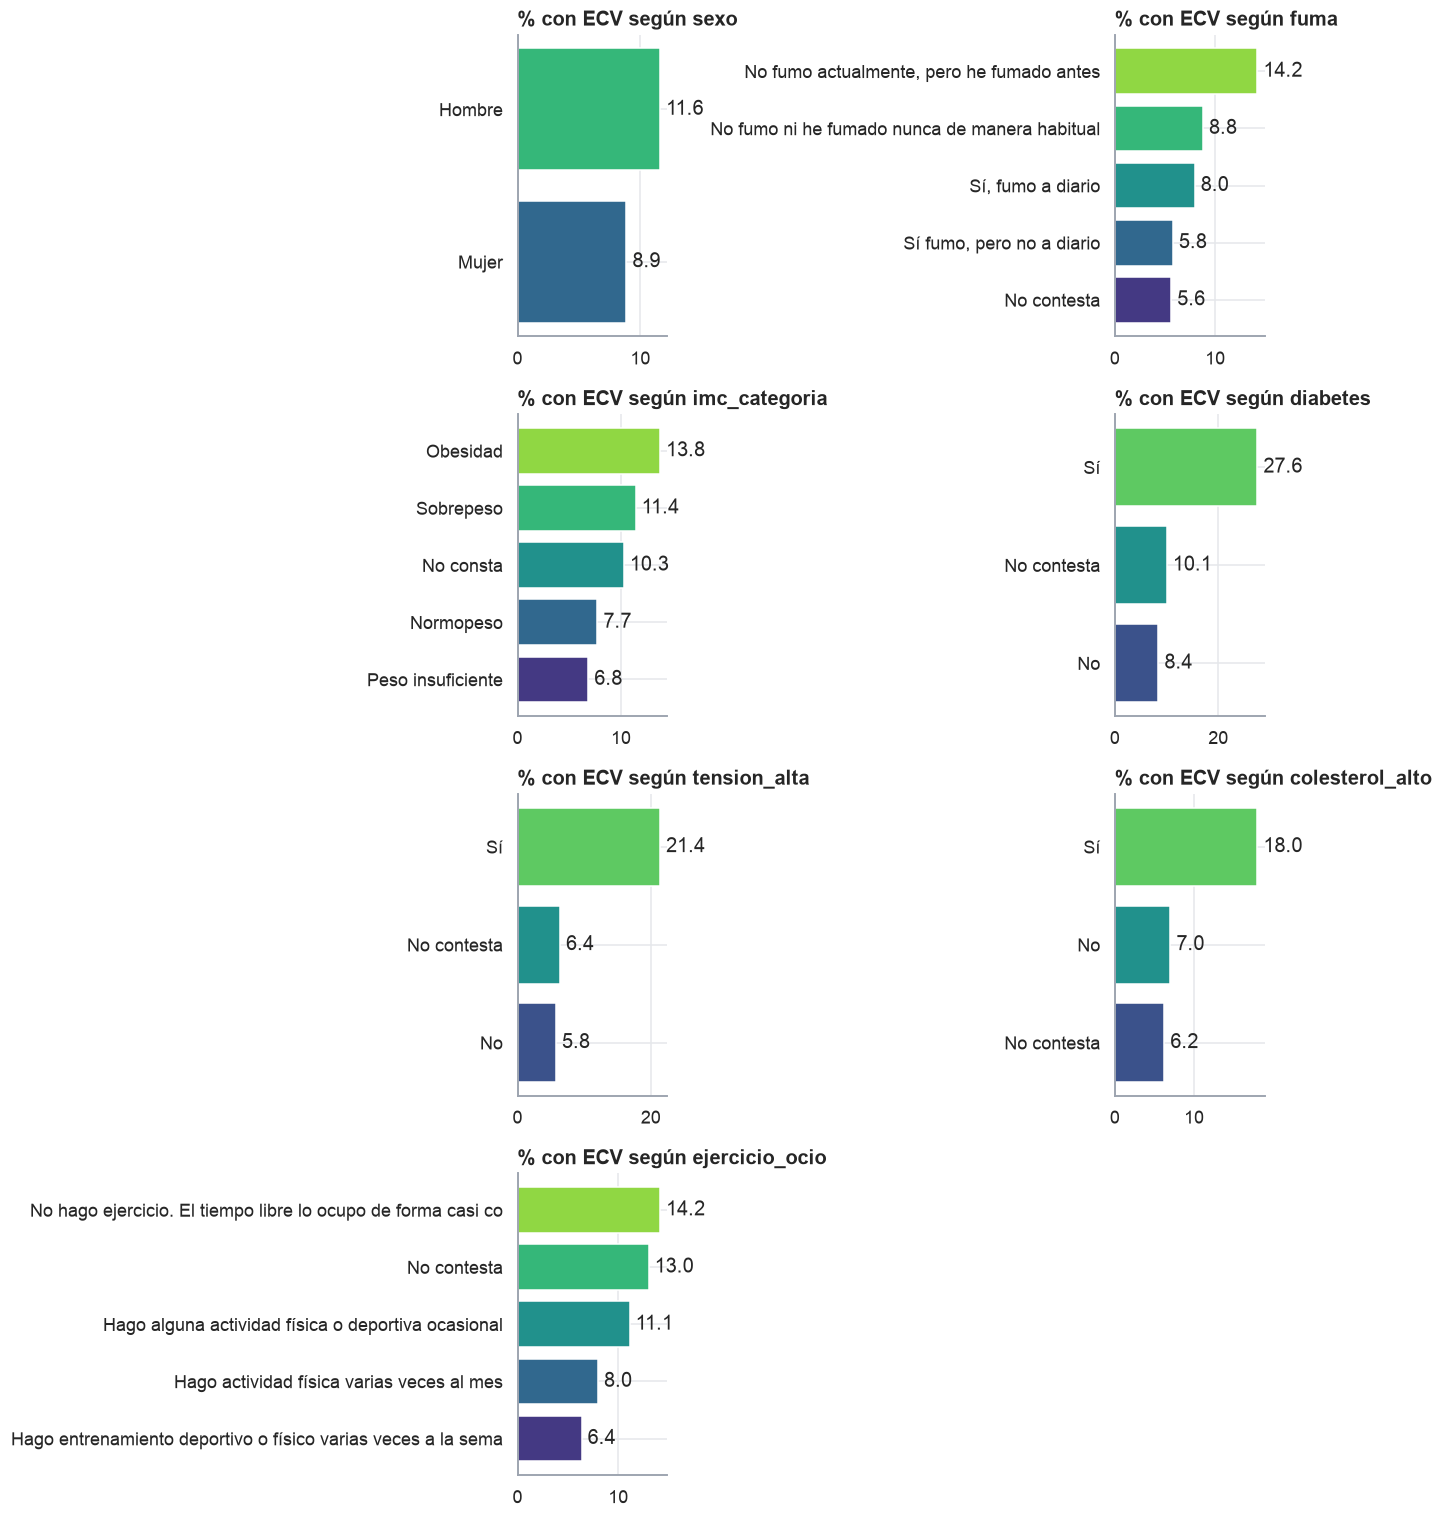

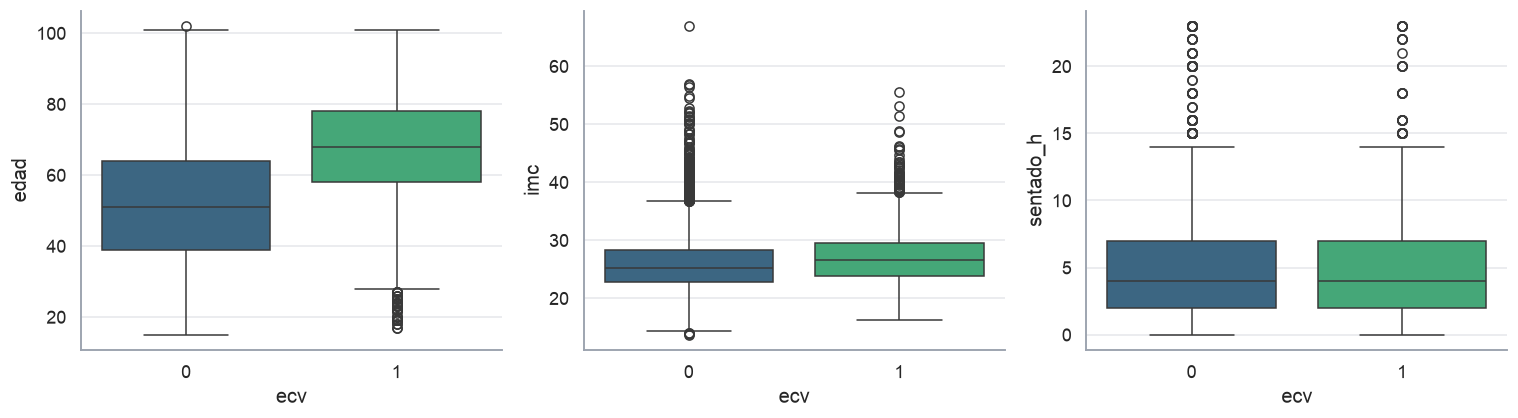

In [16]:
# 1. Variable objetivo
sns.countplot(x="ecv", hue="ecv", data=df, palette=PALETA, legend=False)
plt.title("Personas sin (0) y con (1) enfermedad cardiovascular", loc="left")
sns.despine()
plt.show()

# 2. ECV por grupo de edad
grupos_edad = pd.cut(df["edad"], bins=[14, 29, 44, 59, 74, 120],
                     labels=["15-29", "30-44", "45-59", "60-74", "75+"])
tasa_edad = df.groupby(grupos_edad, observed=True)["ecv"].mean().mul(100)
plt.figure(figsize=(7, 4))
grafico_barras(tasa_edad, "% con ECV por grupo de edad", ordenar=False)
plt.ylabel("% con ECV")
plt.show()

# 3. ECV según variables clave (con etiquetas legibles)
claves = ["sexo", "fuma", "imc_categoria", "diabetes", "tension_alta",
          "colesterol_alto", "ejercicio_ocio"]
fig, ejes = plt.subplots(4, 2, figsize=(12, 14))
for ax, col in zip(ejes.flatten(), claves):
    tasa = df["ecv"].groupby(df_etiquetas[col]).mean().mul(100)
    grafico_barras(tasa, f"% con ECV según {col}", horizontal=True, ax=ax)
ejes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

# 4. Variables numéricas frente a la ECV
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(ejes, ["edad", "imc", "sentado_h"]):
    sns.boxplot(x="ecv", y=col, hue="ecv", data=df, palette=PALETA, legend=False, ax=ax)
plt.tight_layout()
plt.show()